# Project Galicia · Plan de creación de valor

El business plan standalone (notebook `Business_Plan_Inditex.ipynb`) responde a «qué hace Inditex si nadie cambia nada». Este notebook responde a «**qué puede añadir el fondo**»: ocho palancas operativas y financieras, cada una con sus hipótesis, su incertidumbre y su efecto en la TIR y en los covenants.

## Cómo se usa

1. Abre `Excels/Inditex_LBO_Rollover50_BusinessPlan.xlsx`, hoja **Palancas**.
2. Cambia las celdas amarillas. Cada parámetro tiene un **barómetro** con cuatro bandas calibradas con datos de las cuentas: azul *Conservador*, verde *Normal*, amarillo *Optimista* y rojo *Agresivo*. La columna «Dato que lo ancla» dice de dónde sale cada rango.
3. El modelo LBO del grupo se recalcula al instante (TIR, MoM, DSCR, EBITDA) en el panel de resultados de arriba. `D4 = 0` apaga el plan; cada palanca tiene su interruptor; el caso operativo se elige en `LBO_Rollover50!F9`.
4. Guarda el Excel y ejecuta este notebook: lee tus valores y calcula lo que Excel no puede, el **riesgo** (20.000 caminos con crisis y riesgo de ejecución) y el **reparto de la TIR por palanca**.

El Excel y este código usan la misma aritmética: se ha comprobado en 28 combinaciones de palancas y casos que coinciden a precisión de máquina.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_colwidth", 90)

from bp import levers as L, plan as PL
from bp.pipeline import build
from bp.analysis import risk_summary
from bp.export import add_plan_sheet

es = lambda v, f: format(v, f).replace(",", "§").replace(".", ",").replace("§", ".")
fig = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))

o = build(figures=False)                              # business plan standalone (20.000 caminos)
EXCEL = ROOT.parent / "Excels" / "Inditex_LBO_Rollover50_BusinessPlan.xlsx"
values, on = PL.read_dashboard(EXCEL) if EXCEL.exists() else (L.default_values(), None)
display(Markdown(f"Valores leídos de **{EXCEL.name if EXCEL.exists() else 'valores por defecto'}**."))

Valores leídos de **Inditex_LBO_Rollover50_BusinessPlan.xlsx**.

In [2]:
rows = []
for lv in L.LEVERS:
    for p in lv.params:
        v = values[lv.key][p.key]
        rows.append({"Palanca": lv.name, "Activa": "sí" if (on is None or on.get(lv.key)) else "no",
                     "Parámetro": p.label, "Valor": v, "Unidad": p.unit, "Banda": p.band(v)})
pd.DataFrame(rows).set_index(["Palanca", "Activa"])

Parámetro  \
Palanca                                       Activa                                                                      
Expansión en EE. UU.                          sí                                                Superficie nueva al año   
                                              sí                                     Ventas por m² de una tienda madura   
                                              sí                          Margen EBITDA pre-IFRS 16 de la tienda madura   
                                              sí                                                   Capex por m² abierto   
                                              sí      Canibalización (ventas que se quitan a otras tiendas y al online)   
Marcas jóvenes (Stradivarius, Oysho, Bershka) sí                                                Superficie nueva al año   
                                              sí                                     Ventas por m² de una tienda madura   
                                              sí                          Margen EBITDA pre-IFRS 16 de la tienda madura   
                                              sí                                                   Capex por m² abierto   
                                              sí      Canibalización (ventas que se quitan a otras tiendas y al online)   
Lefties frente a Shein y Temu                 sí                                                Superficie nueva al año   
                                              sí                                     Ventas por m² de una tienda madura   
                                              sí                          Margen EBITDA pre-IFRS 16 de la tienda madura   
                                              sí                                                   Capex por m² abierto   
                                              sí      Canibalización (ventas que se quitan a otras tiendas y al online)   
Optimización de tiendas adicional             sí                       Superficie reformada o ampliada adicional al año   
                                              sí                               Aumento de ventas por m² en lo reformado   
                                              sí                                                 Capex por m² reformado   
                                              sí                                  Margen sobre las ventas incrementales   
Eficiencia operativa                          sí                                             Ahorro de gastos a régimen   
                                              sí                                 Años hasta alcanzar el ahorro completo   
                                              sí                                                  Coste de implantación   
Circulante                                    sí                                           Más proveedores sobre ventas   
                                              sí                                         Menos existencias sobre ventas   
Venta y realquiler de inmuebles (PropCo)      sí                             Parte de terrenos y construcciones vendida   
                                              sí                                      Valor de mercado / valor contable   
                                              sí                         Rentabilidad que exige el comprador (cap rate)   
Dividendo financiado con deuda (recap)        sí                               Deuda senior neta objetivo tras el recap   
                                              sí                                                          Año del recap   

                                                          Valor  \
Palanca                                       Activa              
Expansión en EE. UU.                          sí        20.0000   
                                              sí      7500.0000   
                            

## 1. Las ocho palancas y cómo se modelan

**Programas de aperturas (EE. UU., marcas jóvenes, Lefties).** Cada año se abren $A$ miles de m². Una añada abierta en el año $k$ vende en el año $t$:

$$\text{Ventas}_{k,t} = A \cdot D \cdot (1-\delta)^{k-1} \cdot \rho^{V}_{t-k}\,(1-c)$$

con $D$ las ventas por m² de una tienda madura, $\rho^{V} = (60\,\%, 85\,\%, 100\,\%)$ la maduración, $\delta = 3\,\%$ los **rendimientos decrecientes** (cada añada ocupa peores ubicaciones) y $c$ la canibalización. El EBITDA aplica el margen maduro con su propia rampa $\rho^{M} = (50\,\%, 80\,\%, 100\,\%)$ y resta el margen del grupo (23,7 %) sobre las ventas canibalizadas. El capex es $A \times$ capex/m² el año de apertura.

**Reformas adicionales.** Ventas extra = m² reformados × 8.445 €/m² (media del grupo) × mejora de productividad, con margen incremental alto porque la tienda ya existe. Solo cuenta lo que supere el programa actual, que ya está en el plan base.

**Eficiencia operativa.** Ahorro en puntos básicos de ventas que llega a régimen en $Y$ años, con un coste de implantación (múltiplo del ahorro anual) pagado en 2026-27.

**Circulante.** Más proveedores y menos existencias sobre ventas (la mitad en 2026, completo desde 2027). Libera caja una vez, sin tocar el EBITDA.

**PropCo.** Se venden terrenos y construcciones (2.404 M€ de valor contable) a valor de mercado y se realquilan. La caja entra como fuente en el cierre (menos equity del fondo) y el alquiler, indexado al 2 %, resta EBITDA pre-IFRS 16 para siempre, también a la salida, multiplicado por 20,8x.

**Recap.** En el año elegido se amplía la TLB hasta la deuda senior neta objetivo y se reparte como dividendo. El fondo cobra antes, pero la deuda sube.

**Riesgo de ejecución (solo en la simulación).** Cada palanca operativa se multiplica en cada camino por un factor triangular (por ejemplo 0,5 / 1,0 / 1,1 en aperturas): lo normal es cumplir el plan, puede salir algo mejor, pero la cola mala es más larga. Además, las ventas nuevas sufren las mismas crisis que el negocio.

In [3]:
PL.catalogue().set_index(["Palanca", "Parámetro"])

Unidad  \
Palanca                                       Parámetro                                                                           
Expansión en EE. UU.                          Superficie nueva al año                                                  miles m²   
                                              Ventas por m² de una tienda madura                                           €/m²   
                                              Margen EBITDA pre-IFRS 16 de la tienda madura                                   %   
                                              Capex por m² abierto                                                         €/m²   
                                              Canibalización (ventas que se quitan a otras tiendas y al online)               %   
Marcas jóvenes (Stradivarius, Oysho, Bershka) Superficie nueva al año                                                  miles m²   
                                              Ventas por m² de una tienda madura                                           €/m²   
                                              Margen EBITDA pre-IFRS 16 de la tienda madura                                   %   
                                              Capex por m² abierto                                                         €/m²   
                                              Canibalización (ventas que se quitan a otras tiendas y al online)               %   
Lefties frente a Shein y Temu                 Superficie nueva al año                                                  miles m²   
                                              Ventas por m² de una tienda madura                                           €/m²   
                                              Margen EBITDA pre-IFRS 16 de la tienda madura                                   %   
                                              Capex por m² abierto                                                         €/m²   
                                              Canibalización (ventas que se quitan a otras tiendas y al online)               %   
Optimización de tiendas adicional             Superficie reformada o ampliada adicional al año                         miles m²   
                                              Aumento de ventas por m² en lo reformado                                        %   
                                              Capex por m² reformado                                                       €/m²   
                                              Margen sobre las ventas incrementales                                           %   
Eficiencia operativa                          Ahorro de gastos a régimen                                           pb de ventas   
                                              Años hasta alcanzar el ahorro completo                                       años   
                                              Coste de implantación                                              × ahorro anual   
Circulante                                    Más proveedores sobre ventas                                                   pp   
                                              Menos existencias sobre ventas                                                 pp   
Venta y realquiler de inmuebles (PropCo)      Parte de terrenos y construcciones vendida                                      %   
                                              Valor de mercado / valor contable                                               x   
                                              Rentabilidad que exige el comprador (cap rate)                                  %   
Dividendo financiado con deuda (recap)        Deuda senior neta objetivo tras el recap                                 x EBITDA   
                                              Año del recap                                                                 año   

                                                           

## 2. ¿Qué pasa si hago todas?

Todas las palancas a la vez, con cada parámetro en el centro de su banda.

In [4]:
p = PL.build_plan(o, values, on)
p["bands"].style.format(lambda v: f"{v:,.0f}" if abs(v) > 100 else f"{v:.1%}" if abs(v) < 1 else f"{v:.2f}")

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


,Sin plan,Todas en Conservador,Todas en Normal,Todas en Optimista,Todas en Agresivo
TIR mediana,4.9%,5.0%,5.9%,8.2%,13.8%
TIR P10,-1.5%,-1.4%,-0.6%,2.0%,7.7%
TIR P90,10.0%,10.1%,10.9%,13.2%,18.7%
MoM mediano,1.27,1.28,1.33,1.48,1.87
P(TIR < 0),14.9%,14.5%,11.6%,6.3%,2.1%
P(TIR ≥ 15 %),0.4%,0.4%,0.9%,3.9%,37.7%
P(TIR ≥ 20 %),0.0%,0.0%,0.0%,0.1%,5.0%
"P(DSCR mínimo < 1,2x)",70.7%,72.6%,71.1%,63.5%,42.0%
"P(DSCR mínimo < 1,0x)",38.2%,40.3%,39.6%,31.8%,22.3%
P(caja < 0 con la RCF agotada),0.3%,0.4%,0.5%,0.4%,0.3%


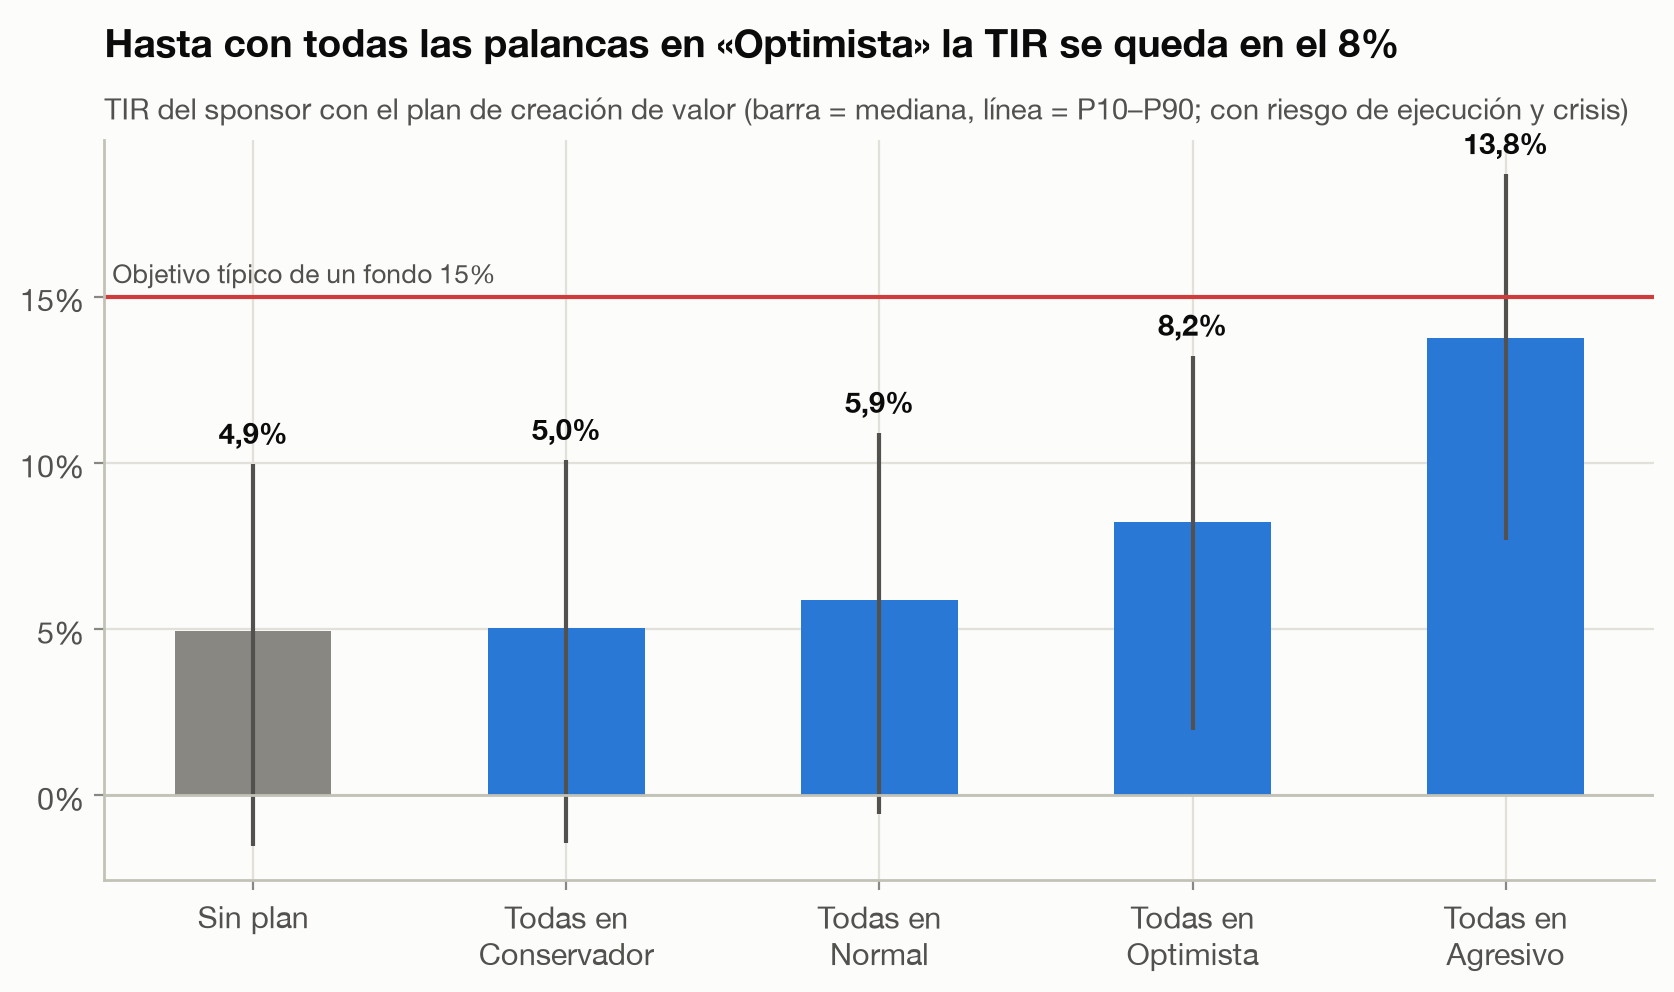

In [5]:
fig("fig10_plan_por_bandas.png")

In [6]:
b = p["bands"]
display(Markdown(f'''
* Con todas las palancas en **Normal** la TIR mediana pasa del {es(b.loc["TIR mediana","Sin plan"], ".1%")} al **{es(b.loc["TIR mediana","Todas en Normal"], ".1%")}**; en **Optimista**, al **{es(b.loc["TIR mediana","Todas en Optimista"], ".1%")}**.
* Solo con todo en **Agresivo** (hipótesis sin precedente en el histórico) la mediana se acerca al 15 % ({es(b.loc["TIR mediana","Todas en Agresivo"], ".1%")}), y aun así P(TIR ≥ 15 %) = {es(b.loc["P(TIR ≥ 15 %)","Todas en Agresivo"], ".0%")}.
* Las palancas **mejoran los covenants**: más EBITDA y menos circulante → P(DSCR < 1,2x) baja del {es(b.loc["P(DSCR mínimo < 1,2x)","Sin plan"], ".0%")} al {es(b.loc["P(DSCR mínimo < 1,2x)","Todas en Optimista"], ".0%")} en Optimista.
'''))


* Con todas las palancas en **Normal** la TIR mediana pasa del 4,9% al **5,9%**; en **Optimista**, al **8,2%**.
* Solo con todo en **Agresivo** (hipótesis sin precedente en el histórico) la mediana se acerca al 15 % (13,8%), y aun así P(TIR ≥ 15 %) = 38%.
* Las palancas **mejoran los covenants**: más EBITDA y menos circulante → P(DSCR < 1,2x) baja del 71% al 64% en Optimista.


## 3. El plan elegido en el panel

Reparto **exacto** de la mejora de la TIR mediana entre palancas con valores de Shapley: se simulan las $2^8 = 256$ combinaciones de palancas encendidas y apagadas y a cada una se le asigna su aportación marginal media. Así se tienen en cuenta las interacciones (por ejemplo, la mejora de circulante también se aplica a las ventas de las tiendas nuevas).

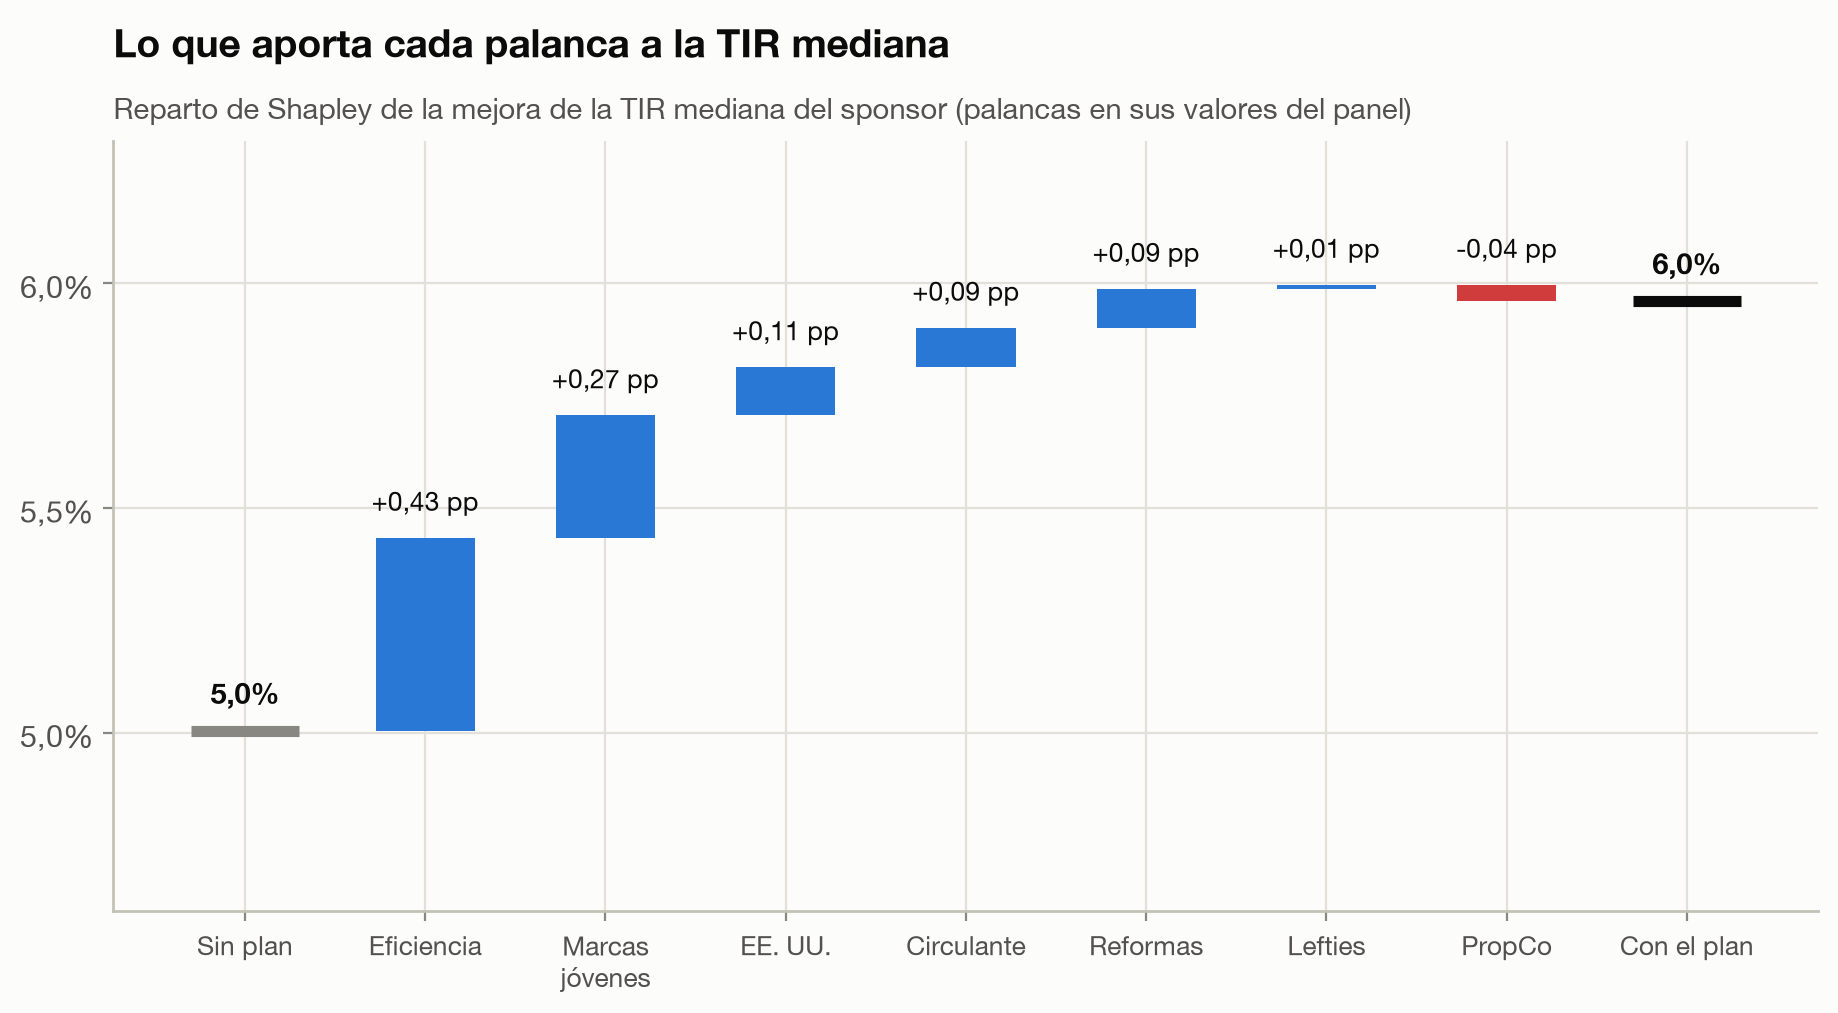

In [7]:
fig("fig11_plan_cascada.png")

In [8]:
p["lever_table"].style.format({"TIR aportada (pp)": "{:+.2f}", "Inversión 2026-30 (€m)": "{:,.0f}",
                               "pb de TIR por cada 100 M€": "{:.1f}", "Δ EBITDA 2030 caso base (€m)": "{:,.0f}"}, na_rep="—")

,TIR aportada (pp),Inversión 2026-30 (€m),pb de TIR por cada 100 M€,Δ EBITDA 2030 caso base (€m)
Palanca,,,,
Eficiencia operativa,+0.43,166,25.8,191
"Marcas jóvenes (Stradivarius, Oysho, Bershka)",+0.27,525,5.2,141
Expansión en EE. UU.,+0.11,600,1.8,74
Circulante,+0.09,0,—,0
Optimización de tiendas adicional,+0.09,400,2.2,54
Lefties frente a Shein y Temu,+0.01,150,0.6,11
Dividendo financiado con deuda (recap),+0.00,0,—,0
Venta y realquiler de inmuebles (PropCo),-0.04,0,—,-79


In [9]:
t = p["lever_table"]
per100 = t["pb de TIR por cada 100 M€"].dropna().sort_values(ascending=False)
display(Markdown(f'''
**Dónde poner el siguiente euro:** {per100.index[0]} ({es(per100.iloc[0], ".1f")} pb de TIR por cada 100 M€) rinde
{es(per100.iloc[0] / per100.iloc[-1], ".0f")} veces más que {per100.index[-1]} ({es(per100.iloc[-1], ".1f")} pb).
La expansión en EE. UU. es la palanca más vistosa, pero exige mucho capex por m² en un mercado donde Inditex ya ganó
menos en 2025 (396 M€ antes de impuestos, -5 %).

**La PropCo resta TIR** con un cap rate del {es(values["propco"]["caprate"], ".2%")}: el comprador exige más rentabilidad
de la que da el negocio comprado a 20,8x (≈ 5 %). Es deuda cara disfrazada de venta de activos. Solo suma si el cap rate
baja de ≈ 4,75 % (pruébalo en el panel).
'''))


**Dónde poner el siguiente euro:** Eficiencia operativa (25,8 pb de TIR por cada 100 M€) rinde
43 veces más que Lefties frente a Shein y Temu (0,6 pb).
La expansión en EE. UU. es la palanca más vistosa, pero exige mucho capex por m² en un mercado donde Inditex ya ganó
menos en 2025 (396 M€ antes de impuestos, -5 %).

**La PropCo resta TIR** con un cap rate del 5,75%: el comprador exige más rentabilidad
de la que da el negocio comprado a 20,8x (≈ 5 %). Es deuda cara disfrazada de venta de activos. Solo suma si el cap rate
baja de ≈ 4,75 % (pruébalo en el panel).


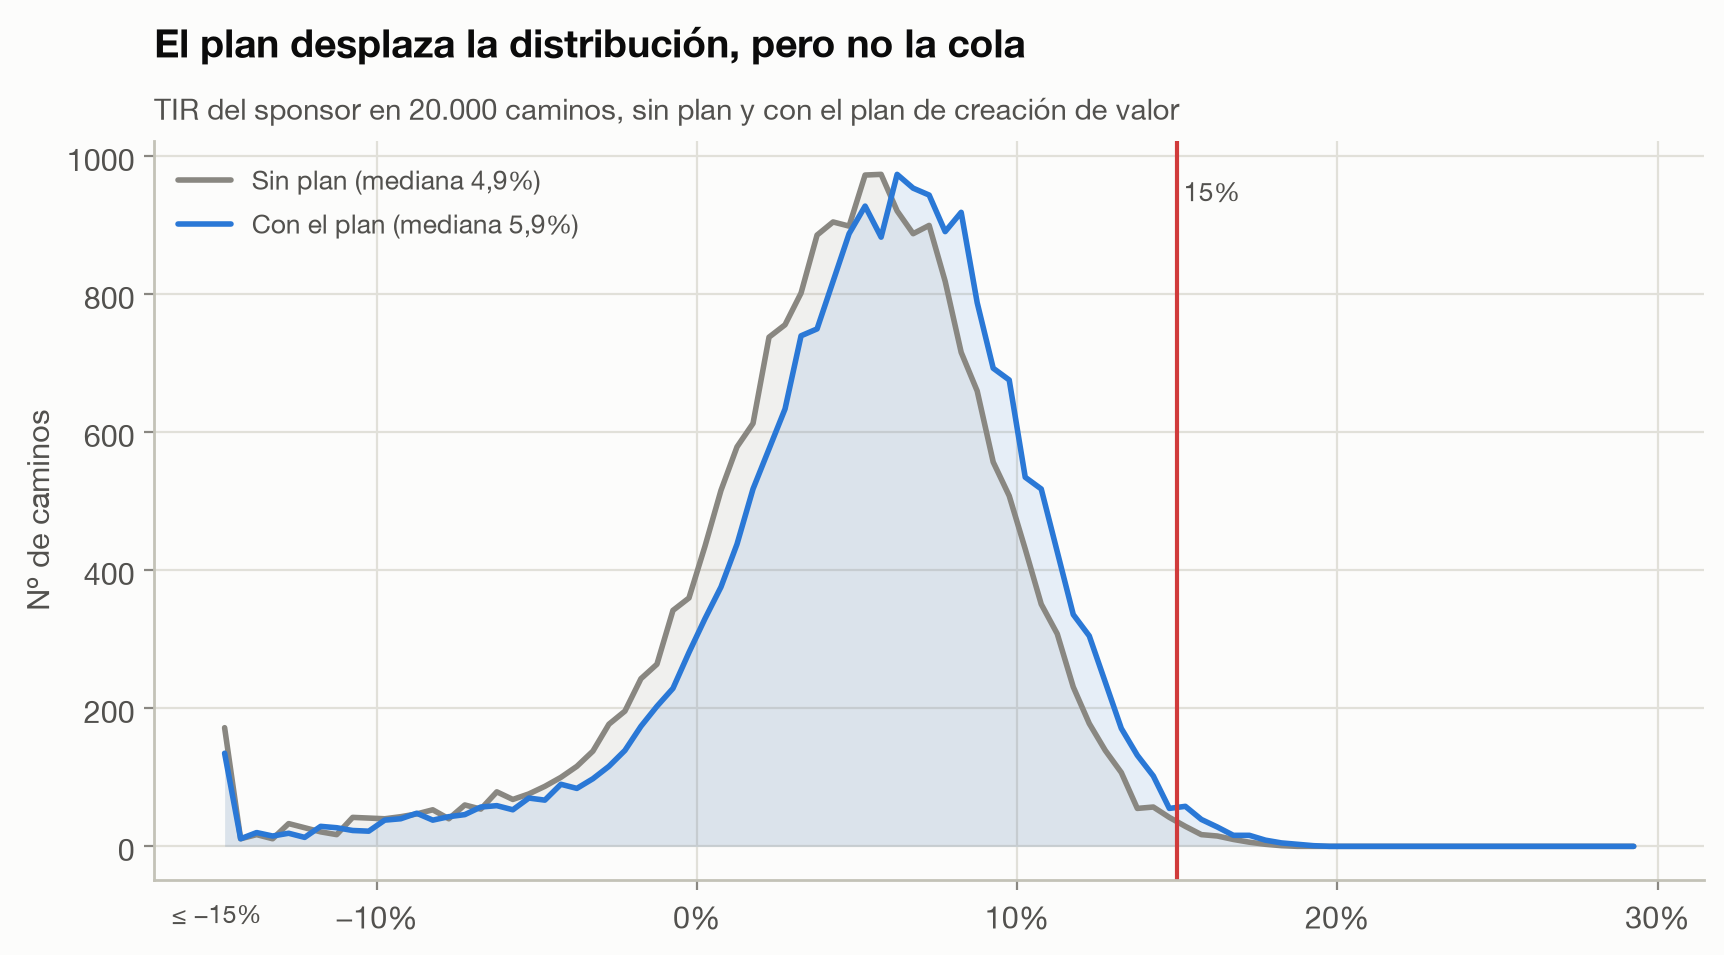

In [10]:
fig("fig12_plan_distribucion.png")

In [11]:
pd.DataFrame({"Sin plan": risk_summary(o["res"]), "Con el plan del panel": risk_summary(p["chosen"]["res"])})

,Sin plan,Con el plan del panel
TIR mediana,0.049497,0.059047
TIR P10,-0.015253,-0.005200
TIR P90,0.099707,0.109290
MoM mediano,1.273397,1.332427
P(TIR < 0),0.148750,0.114350
P(TIR ≥ 15 %),0.004050,0.008750
P(TIR ≥ 20 %),0.000000,0.000000
"P(DSCR mínimo < 1,2x)",0.706850,0.709000
"P(DSCR mínimo < 1,0x)",0.381700,0.394150
P(caja < 0 con la RCF agotada),0.003100,0.005150


## 4. Mensaje para la presentación

1. El plan de creación de valor **sí mejora la operación** (más TIR y mejores covenants), y la prioridad es clara: eficiencia, circulante y marcas de alto ROCE antes que la expansión en EE. UU.
2. Pero **no cambia la conclusión**: a 20,8x EBITDA de entrada, llegar al 15 % exige que todo salga en la banda agresiva. El problema es el precio, no el plan.
3. Las palancas financieras (PropCo, recap) no crean valor por sí solas: mueven caja en el tiempo y añaden riesgo.

## 5. Exportación

In [12]:
out = ROOT / "output" / "Business_Plan_Inditex.xlsx"
print(add_plan_sheet(p, out).relative_to(ROOT.parent))

Business Plan/output/Business_Plan_Inditex.xlsx
